# Variational Autoencoders Part 1: Probabilistic PCA

**Vanessa Gómez Verdejo,  Pablo Martínez Olmos, Alejandro Lancho Serrano**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
!pip install pytorch-model-summary

# Introduction to Latent Variable Models  

In previous sessions, we explored how to approximate $p({\bf x})$ using autoregressive models (ARMs). These models factorize the distribution and parameterize the conditional probabilities as follows:  

$$ p({\bf x}) = \prod_{d=1}^{D} p(x_d \mid x_{<d}) $$

In this session, we take a different approach by reconstructing  $p({\bf x})$  using latent variables.  



## Intuition Behind Latent Variable Models  

Suppose we have a dataset of human face images and we want to learn  $p({\bf x})$ to generate new, realistic faces. Before formally addressing this problem, we can ask ourselves: **how should we generate a human face?** Or, in other words, if we were a generative model, how would we do it?  

A natural strategy could be:  

1. First, define the overall structure of the face, including the shape of the head and the positioning of facial features.  
2. Then, determine specific characteristics such as eye shape, nose structure, and lip contours.  
3. Assign colors for skin tone, eye color, and hair.  
4. Finally, add fine details, such as lighting effects, textures, and background elements.  

In general, we can say that certain **key factors** in the data (such as facial shape, hairstyle, skin tone, or background) are crucial for generating a realistic image. Once these factors are determined, we can generate a face by progressively adding details.  

Now, we will use mathematics to formalize this generative process.  




## Mathematical Formulation  

Instead of modeling $\bf x $ directly, we introduce a **latent variable** $\bf z $ that represents hidden factors in the data. Mathematically, we consider a high-dimensional object ${\bf x}  \in \mathcal{X}^D $ (e.g., an image where pixel values belong to $\mathcal{X} = \{0, 1, \dots, 255\} $) and a lower-dimensional latent variable ${\bf z} \in \mathcal{Z}^M $ (e.g., $ \mathcal{Z} = \mathbb{R}^M $). We can refer to $ \mathcal{Z}^M $ as a **low-dimensional manifold** or the **latent space**.  

The generative process is then expressed as:  

1. **Sample a latent variable**:  
   $$   {\bf z} \sim p({\bf z})$$
2. **Generate an observation from the latent variable**:  
   $$ {\bf x}\sim p({\bf x}\mid {\bf z}, \theta)$$  


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_1.png" width=60%>

This formulation naturally follows the intuitive generative process described earlier. However, during training, we only have access to ${\bf x}$, not ${\bf z}$. According to probabilistic inference, we must marginalize out the unknown latent variable ${\bf z}$, leading to the **marginal likelihood function**:  

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In practice, we do not have just a single observation $ \mathbf{x} $, but rather a dataset with $ N$ independent observations $ \{ \mathbf{x}^{(i)} \}_{i=1}^{N} $. Given these observations, we adjust the model parameters by maximizing the **joint likelihood** over all data points:  

$$
p(\mathbf{x}^{(1)}, \mathbf{x}^{(2)}, \dots, \mathbf{x}^{(N)}\mid \theta) = \prod_{i=1}^{N} p(\mathbf{x}^{(i)} \mid \theta)
$$

Since each $ p(\mathbf{x}^{(i)}) $ is computed by marginalizing over the latent variable $ \mathbf{z}^{(i)}$, the marginal likelihood function takes the form:  

$$
\mathcal{L}(\theta) = \prod_{i=1}^{N} \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}, \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$

where $\theta$ are the model parameters that allow us to relate the latent variables to the observations. To facilitate optimization, it is common to maximize the **log-likelihood**, which transforms the product into a sum:  

$$
\log \mathcal{L}(\theta) = \sum_{i=1}^{N} \log \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}; \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$



## Challenges and Approaches  

But, **how can we compute this integral?**

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In general, evaluating this integral exactly is challenging. There are two main approaches:  

1. **If the integral is tractable**, we can compute $p({\bf x})$ exactly. A specific case where this is possible is **Probabilistic PCA**, which will be our starting point.  
2. **If the integral is intractable**, we need approximate inference techniques. One of the most powerful methods for efficiently approximating this integral is **Variational Inference (VI)**. This idea is at the core of **Variational Autoencoders (VAEs)** as we will see later.


# Probabilistic Principal Component Analysis (PPCA)

In the previous section, we introduced latent variable models as a framework for structuring data generation processes. Now, we delve into Probabilistic PCA (PPCA), a particular case where all variables follow a Gaussian distribution and the relationship between the observed variables $ \mathbf{x}$ and the latent variables $ \mathbf{z}$ is **linear**. This linearity allows us to derive analytical solutions for the model parameters, making computations straightforward.

## Generative Model

Let us consider the following assumptions:  

- The observed variable $ \mathbf{x} \in \mathbb{R}^D $ is generated from a lower-dimensional latent variable $\mathbf{z} \in \mathbb{R}^M $, where typically $ M < D $.  
- The latent variable follows a **standard Gaussian prior**:  

  $$ p(\mathbf{z}) = \mathcal{N}(\mathbf{z} \mid \mathbf{0}, \mathbf{I}) $$  

- The observed variable $ \mathbf{x} $ is modeled as a **linear transformation** of $\mathbf{z} $, with additive Gaussian noise:  

  $$ \mathbf{x} = \mathbf{W} \mathbf{z} + \mathbf{\mu} + \mathbf{\epsilon} $$  

  where:  
  - $\mathbf{W} $ is a $ D \times M$ matrix defining the **linear mapping** from latent space to data space.  
  - $ \mathbf{\mu} $ is a $ D $-dimensional mean vector representing the average of the observed data.  
  - $ \mathbf{\epsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I}) $ is an isotropic Gaussian noise term modeling variability not captured by the latent space.  


This generative process can be summarized as:


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_7.png" width=60%>


## Marginal Likelihood   

Given the generative process, the conditional distribution of $ \mathbf{x} $ given $\mathbf{z}$ is Gaussian:  

$$ p(\mathbf{x} \mid \mathbf{z}, \theta) = \mathcal{N}(\mathbf{x} \mid \mathbf{W} \mathbf{z} + \mathbf{\mu}, \sigma^2 \mathbf{I}) $$  

where $\theta$ compriss all model parameters, $\theta =[ \mathbf{W}, \mathbf{\mu}, \sigma ]$.
To obtain the **marginal likelihood** of  $\mathbf{x}$, we integrate out the latent variable:  

$$ p(\mathbf{x}\mid \theta) = \int p(\mathbf{x} \mid \mathbf{z},  \theta) p(\mathbf{z}) \, d\mathbf{z} $$  

Since both terms in the integral are Gaussian, the resulting marginal distribution is also Gaussian:  

$$ p(\mathbf{x}\mid \theta) = \mathcal{N}(\mathbf{x} \mid \mathbf{\mu}, \mathbf{C}) $$  

where the covariance matrix is:  

$$ \mathbf{C} = \mathbf{W} \mathbf{W}^T + \sigma^2 \mathbf{I} $$  

This formulation provides a probabilistic extension of PCA, where the variance term $\sigma^2$ accounts for noise in the observations.  


## Maximum Likelihood Estimation of Parameters  

To learn the parameters $\mathbf{W}$, $\mathbf{\mu}$, and $ \sigma^2$, we maximize the **log-likelihood** given a dataset $ \mathbf{X} = \{\mathbf{x}^{(i)}\}_{i=1}^{N} $:  

\begin{align}
\log p(\mathbf{X} \mid \theta) &= \sum_{i=1}^{N} \log p(\mathbf{x}^{(i)} \mid \theta) \\
&= -\frac{ND}{2} \log(2\pi) - \frac{N}{2} \log |\mathbf{C}| - \frac{1}{2} \sum_{i=1}^{N} (\mathbf{x}^{(i)} - \mathbf{\mu})^T \mathbf{C}^{-1} (\mathbf{x}^{(i)} - \mathbf{\mu})
\end{align}  

There are different ways to estimate these parameters:  

1. **Gradient-based optimization** using libraries like PyTorch or TensorFlow.  
2. **Iterative Expectation-Maximization (EM) algorithm**, which provides an efficient way to iteratively estimate $\mathbf{W} $ and $\sigma^2 $.  
3. **Closed-form solution** by setting the gradients to zero and solving explicitly.  


### Analytical Solution

By computing the gradients and setting them to zero, we obtain:  

\begin{align}
\mathbf{\mu}_{\text{ML}} &= \frac{1}{N} \sum_{i=1}^{N} \mathbf{x}^{(i)} = \overline{\mathbf{x}} \\  
\sigma^2_{\text{ML}} &= \frac{1}{D-M} \sum_{i=M+1}^{D} \lambda_i \\  
\mathbf{W}_{\text{ML}} &= \mathbf{U}_{M} \left( \mathbf{L}_{M} - \sigma^2_{\text{ML}} \mathbf{I} \right)^{1/2} \mathbf{R}  
\end{align}  

where:  

- $ \mathbf{U}_M$ contains the **top $M $ eigenvectors** of the empirical covariance matrix $ \mathbf{C}_{XX} $.  
- $ \mathbf{L}_M $ is a diagonal matrix with the **top $M$ eigenvalues** $ \lambda_1, \dots, \lambda_M $.  
- $ \mathbf{R} $ is an arbitrary **orthogonal rotation matrix**, indicating that any rotation of this space is a valid solution.  

## Posterior Distribution: Latent Space Representation

While traditional PCA is usually formulated as a **projection** from data space onto a lower-dimensional subspace, **Probabilistic PCA** provides a **generative mapping** from the latent space to the data space.  

To obtain the latent representation of an observation $ \mathbf{x} $, we compute the posterior distribution using **Bayes’ theorem**:  

$$ p(\mathbf{z} \mid \mathbf{x}) = \frac{p(\mathbf{x} \mid \mathbf{z}) p(\mathbf{z})}{p(\mathbf{x})} $$  

Since all distributions involved are Gaussian, the posterior is also Gaussian:  

$$ p(\mathbf{z} \mid \mathbf{x}) = \mathcal{N}(\mathbf{z} \mid \mathbf{A}^{-1} \mathbf{W}^T (\mathbf{x} - \mathbf{\mu}), \sigma^{-2} \mathbf{A}) $$  

where  

$$ \mathbf{A} = \mathbf{W}^T \mathbf{W} + \sigma^2 \mathbf{I} $$  

Note that, for a given observation $\mathbf{x}_i$, we can calculate its distribution over the latent factors. For instance, its **expected latent representation**  is:  

$$ \mathbb{E}[\mathbf{z}_i \mid \mathbf{x}_i] = \mathbf{A}_{ML}^{-1} \mathbf{W}_{ML}^{\top} (\mathbf{x}_i - \mu_{ML}) $$  




### **Connection to Standard PCA**  

If we set $ \sigma^2 = 0 $ and assume no rotation ($\mathbf{R} = \mathbf{I} $), then:  

$$ \mathbf{W} = \mathbf{U}_{M} \mathbf{L}^{1/2} $$  

so the expectation simplifies to:  

$$ \mathbb{E}[\mathbf{z}_i \mid \mathbf{x}_i] = \mathbf{U}_{M} \mathbf{L}^{1/2} (\mathbf{x}_i - \mu) $$  

This shows that in the limit, **Probabilistic PCA recovers the classical PCA solution**, where the principal components are given by the **dominant eigenvectors** of the data covariance matrix, but scaled by their corresponding eigenvalues.  

### Example: Probabilistic PCA over images of Hand-written digits


#### Load dataset

We are going to use The standard handwritten digits dataset, composed of 28x28 grayscale images and consisting of 60,000 training samples and 10,000 testing samples

In [3]:
import torch
from torchvision import datasets, transforms

# Define transformations
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # MNIST dataset normalization
])

# Cargar el dataset MNIST
mnist_raw = datasets.MNIST(root='.', train=True, download=True, transform=mnist_transform)

# Obtener todas las imágenes y etiquetas
digits = torch.stack([mnist_raw[i][0].view(-1) for i in range(len(mnist_raw))]).numpy()
target = mnist_raw.targets.numpy()

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 488kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.64MB/s]


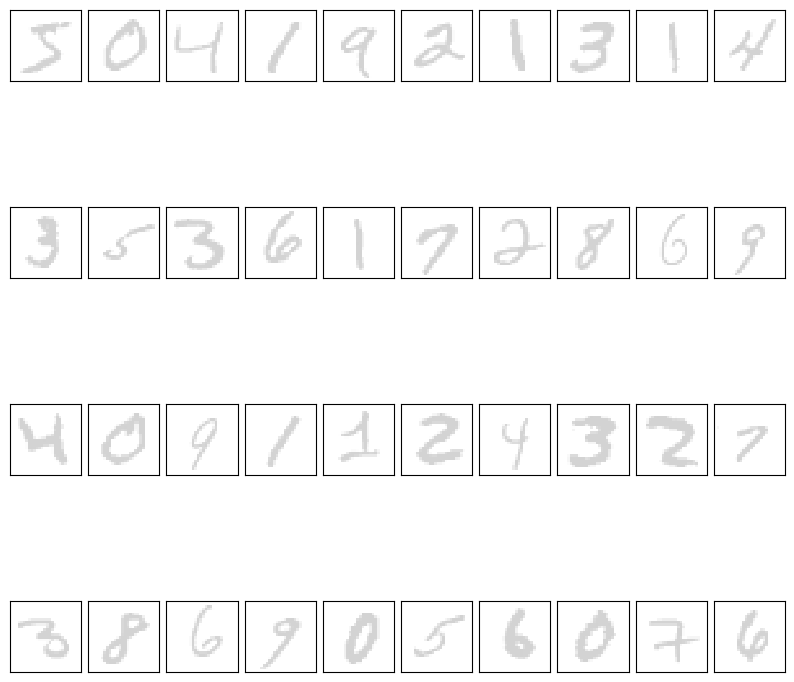

In [4]:
def plot_digits(data):
    fig, axes = plt.subplots(4, 10, figsize=(10, 10),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(28, 28),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))

plot_digits(digits)

Let's compute the analytical solution for a 2D latent space. Remind:


\begin{align}
\mathbf{\mu}_{\text{ML}} &= \overline{\mathbf{x}}=\frac{1}{N}\sum_{i=1}^{N}\mathbf{x}^{(i)}\\
\\
\sigma^2_{\text{ML}} &= \frac{1}{D-M}\sum_{i=M+1}^{D}\lambda_i\\
\\
\mathbf{W}_{\text{ML}} &=\mathbf{U}_{M} \left( \mathbf{L}_{M} - \sigma^2_{\text{ML}}\mathbf{I}\right)^{1/2} \mathbf{R}
\end{align}

So, let's start computing the covariance matrix of the data and analyzing the eigenvalues

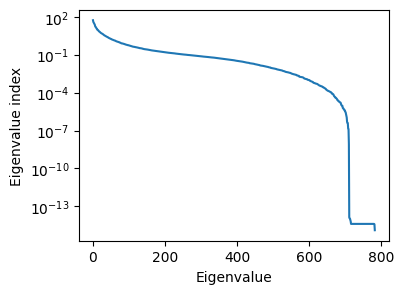

In [5]:
plt.figure(figsize=(4,3))

N, D = digits.shape

S = np.cov(digits.T)

u, s, vh = np.linalg.svd(S)

plt.semilogy(s)
plt.ylabel('Eigenvalue index')
plt.xlabel('Eigenvalue')
plt.show()

In [6]:
n_components = 2

mu_ML = np.mean(digits,0)
U_m = u[:,:n_components]
L_m = np.diag(s[:n_components])

sigma2_ML = 1./(D-n_components)*np.sum(s[n_components:])

#sigma2_ML = 1.0

W_ML = U_m @(L_m - sigma2_ML*np.eye(n_components))**(1/2)@np.eye(n_components)  # We consider R is the identity



Now, let's use the posterior mean, to project the data

In [7]:
M = W_ML.T@W_ML + sigma2_ML*np.eye(n_components)

mean_projected = np.transpose(np.linalg.pinv(M)@W_ML.T@(digits.data-mu_ML).T)

And now we plot the 2D projection of the numbers ...

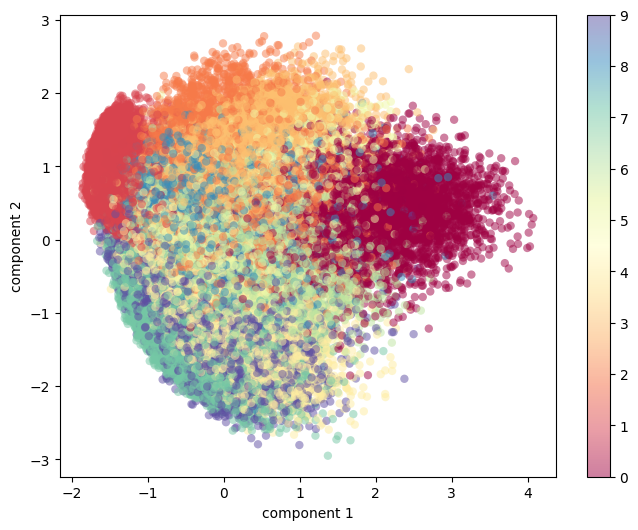

In [8]:
plt.figure(figsize=(8,6))

plt.scatter(mean_projected[:, 0], mean_projected[:, 1],
            c=target, edgecolor='none', alpha=0.5,
            cmap=plt.cm.Spectral)
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar()
plt.show()

### Sampling from the model

Now, that we have estimated the model parameters, we can use the generative model

$$ \mathbf{x}  = \mathbf{W}\mathbf{z}+\mathbf{\mu} +\epsilon$$

where

$$p(\mathbf{z})=\mathcal{N}(\mathbf{z}|\mathbf{0},\mathbf{I})$$

and

$$p(\mathbf{\epsilon})=\mathcal{N}(\mathbf{\epsilon}|\mathbf{0},\sigma^2 \bf{I})$$

to sample from the model, with $\mathbf{W}=\mathbf{W}_{ML}$, $\mathbf{\mu}=\mathbf{\mu}_{ML}$ and $\sigma=\sigma_{ML}$, to observe the quality of the pdf estimation ...


In [9]:
n_samples = 40

s = np.random.randn(n_components,n_samples)

mean_x_given_s = W_ML@s + mu_ML.reshape([-1,1])

samples = mean_x_given_s + sigma2_ML *np.random.randn(D,n_samples)


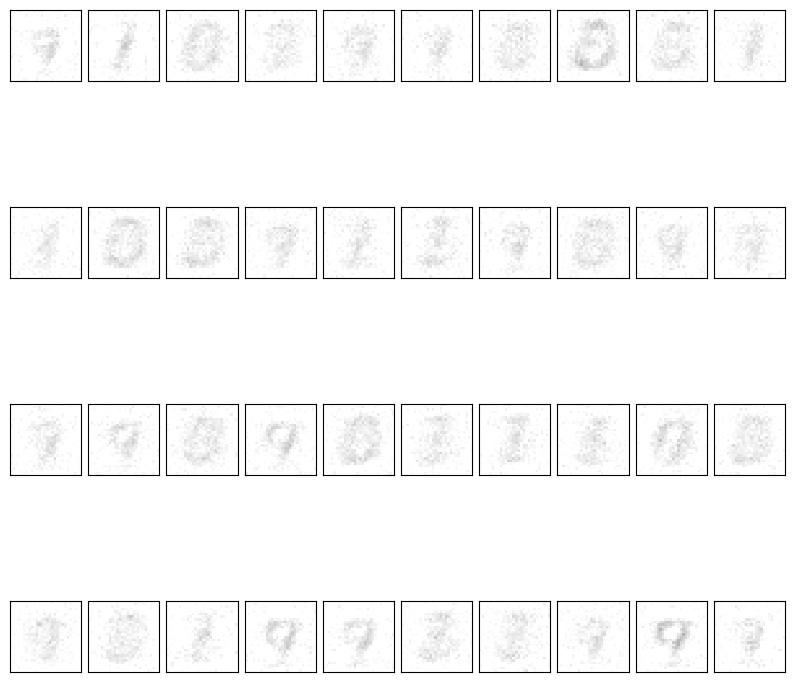

In [10]:
plot_digits(samples.T)

Let's increase the dimension of the latent space to see if image generation improves ...

In [11]:
u, s, vh = np.linalg.svd(S)

n_components = 64

mu_ML = np.mean(digits.data,0)
U_m = u[:,:n_components]
L_m = np.diag(s[:n_components])

sigma2_ML = 1./(D-n_components)*np.sum(s[n_components:])

#sigma2_ML = 1.0

W_ML = U_m @(L_m - sigma2_ML*np.eye(n_components))**(1/2)@np.eye(n_components)


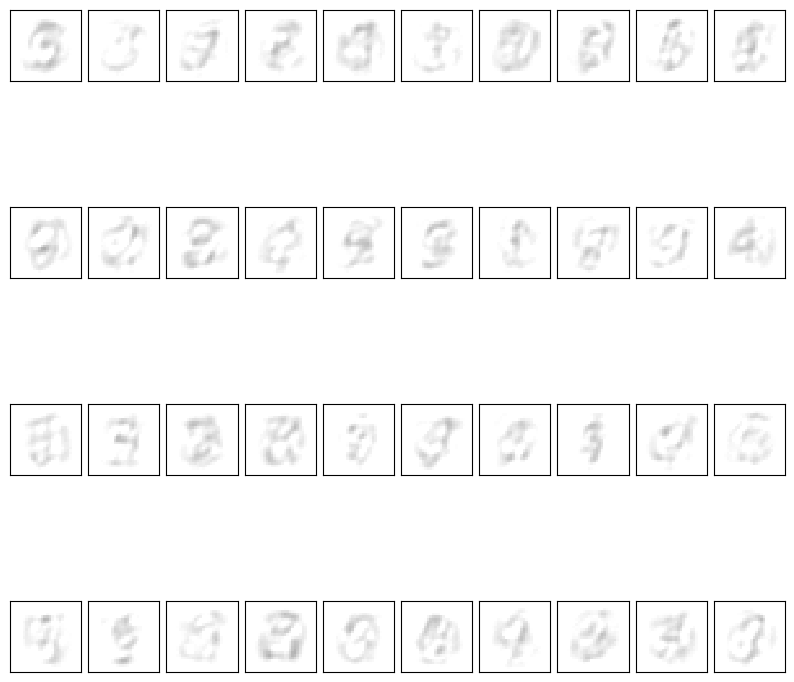

In [12]:
n_samples = 64

s = np.random.randn(n_components,n_samples)

mean_x_given_s = W_ML@s + mu_ML.reshape([-1,1])

samples = mean_x_given_s + sigma2_ML* np.random.randn(D,n_samples)

plot_digits(samples.T)

It certainly represents an improvement, but there is still room for enhancement...
Note that the model we're using is linear, which severely limits its expressive power. Additionally, we are modeling pixel values (which are integer and positive) as a Gaussian distribution.

* What would happen if we introduced non-linear dependencies?
* Or if we used distributions other than Gaussians?

In these cases, we would no longer be able to compute the integral exactly, and some form of approximation would be required. In the following section, we will explore how to overcome these limitations using Variational Inference (VI) through the use of Variational Autoencoders (VAEs).